In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.6"
import sys
sys.path.append("/system/user/volkmann/vectorized_autobounds/")

In [4]:
import matplotlib.pyplot as plt
%matplotlib inline
import jax
jax.config.update("jax_enable_x64", True)  # Enable 64-bit precision

import jax.numpy as jnp
import jax.random as jr
import optax
import math

import k3d
import numpy as np
from matplotlib.colors import ListedColormap

In [5]:
from shapes.kdtree_surface import KDTreeSurface
from shapes.sdf import SDF
from solver.WoS import WoSSolver
from implicitSurfaces.autoboundedImplicit import autoboundedImplicit
from implicitSurfaces.lipschitzImplicit import sdfImplicit, lipschitzImplicit
from surfaceTrace.meshRefinement import  meshRefinement

from functools import partial
from utils.helpers import mesh_3d, mesh_to_vec_3d
from typing import Callable

ModuleNotFoundError: No module named 'drjit'

## functions

In [4]:
t = jnp.ones((3))
m = jnp.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])

jnp.matmul(m, t)

Array([ 6., 15., 24.], dtype=float64)

In [5]:
@partial(jax.jit, static_argnames=['radius'])
def sdf_sphere_jax(x: jnp.ndarray, radius: float) -> jnp.ndarray:
    return jnp.linalg.norm(x, axis=-1) - radius


@partial(jax.jit, static_argnames=['r', 'R'])
def sdf_torus_jax(x: jnp.ndarray, r: float, R: float) -> jnp.ndarray:
    q = jnp.sqrt(jnp.pow(x[0], 2) + jnp.pow(x[2], 2)) - R
    return jnp.sqrt(jnp.pow(q, 2) + jnp.pow(x[1], 2)) - r

def twistOperation(fn: Callable, k: float) -> Callable:
    @jax.jit
    def twist(x: jnp.array):
        c = jnp.cos(k * x[1])
        s = jnp.sin(k * x[1])
        m = jnp.array([[c, 0., -s], [s, 0., c], [0., 1., 0.]])
        return fn(jnp.matmul(m, x))
    return twist

In [6]:
from typing import NamedTuple

class Params(NamedTuple):
    w1: jnp.ndarray  # [d_in, d_hidden]
    b1: jnp.ndarray  # [d_hidden]
    w2: jnp.ndarray  # [d_hidden, d_hidden]
    b2: jnp.ndarray  # [d_hidden]
    w3: jnp.ndarray  # [d_hidden, d_hidden]
    b3: jnp.ndarray  # [d_hidden]
    w4: jnp.ndarray  # [d_hidden, d_out]
    b4: jnp.ndarray  # [d_out]


def init_params(d_in, d_hidden, d_out, key):
    w1_key, w2_key, w3_key, w4_key, b1_key, b2_key, b3_key, b4_key = jax.random.split(key, num=8)
    return Params(
        w1=jax.random.uniform(key=w1_key, shape=[d_in, d_hidden], minval=-1/math.sqrt(d_in), maxval=1/math.sqrt(d_in)),
        b1=jax.random.uniform(key=b1_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w2=jax.random.uniform(key=w2_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b2=jax.random.uniform(key=b2_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w3=jax.random.uniform(key=w3_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b3=jax.random.uniform(key=b3_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w4=jax.random.uniform(key=w4_key, shape=[d_hidden, d_out], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b4=jax.random.uniform(key=b4_key, shape=[d_out], minval=-1/math.sqrt(d_out), maxval=1/math.sqrt(d_out)),
    )


def neural_network(params, x):
    x = x @ params.w1 + params.b1
    x = jax.nn.swish(x)
    x = x @ params.w2 + params.b2
    x = jax.nn.swish(x)
    x = x @ params.w3 + params.b3
    x = jax.nn.swish(x)
    x = x @ params.w4 + params.b4

    return x

In [7]:
def train(model, params, optim, ndim, gt_fn, n_steps, bbox, subkey):
    opt_state = optim.init(params)

    def loss_fn(params, X):
        pred_y = jax.vmap(model, in_axes=(None, 0))(params, X)
        true_y = jax.vmap(gt_fn)(X)
        return jnp.mean(jnp.pow((pred_y[:, 0] - true_y), 2))

    @jax.jit
    def step(params, opt_state, X):
        loss, grads = jax.value_and_grad(loss_fn, argnums=0)(params, X)
        update, opt_state = optim.update(grads, opt_state)
        params = optax.apply_updates(params, update)
        return params, opt_state, loss
    
    @jax.jit
    def point_sampler(key):
        key, subkey = jax.random.split(key)
        return jax.random.uniform(key, (10000, ndim), minval=bbox[0], maxval=bbox[1]), subkey

    for iter in range(0, n_steps):
        XY, subkey = point_sampler(subkey)
        params, opt_state, loss = step(params, opt_state, XY)
        if iter % 100 == 0:
            print(f"Iteration {iter}, loss: {loss}")
    return params

### train the model

In [8]:
LEARNING_RATE = 1e-2
STEPS = 2000
RADIUS = 0.5
RADIUS_INNER = 0.2
NDIM = 3
HIDDEN_DIM = 128

params = init_params(NDIM, HIDDEN_DIM, 1, key=jax.random.PRNGKey(1))
trained_params = init_params(NDIM, HIDDEN_DIM, 1, key=jax.random.PRNGKey(2))
optim = optax.adam(LEARNING_RATE)

In [9]:
trained_params = train(
    model=neural_network,
    params=params,
    optim=optim,
    ndim=NDIM,
    gt_fn=twistOperation(partial(sdf_torus_jax, r=RADIUS_INNER, R=RADIUS), k=5.),
    n_steps=STEPS,
    bbox=(-1, 1),
    subkey=jax.random.PRNGKey(0)
)

Iteration 0, loss: 0.07253157730667024
Iteration 100, loss: 0.018339494139976223
Iteration 200, loss: 0.01773830886025419
Iteration 300, loss: 0.01744920235857722
Iteration 400, loss: 0.013476172853124987
Iteration 500, loss: 0.01193957534919173
Iteration 600, loss: 0.005153241516816891
Iteration 700, loss: 0.0015481502761929568
Iteration 800, loss: 0.000845985246950977
Iteration 900, loss: 0.0005736632693658498
Iteration 1000, loss: 0.00035118769743992557
Iteration 1100, loss: 0.00033043261028992344
Iteration 1200, loss: 0.00029380898391225837
Iteration 1300, loss: 0.0003731414753492259
Iteration 1400, loss: 0.0002522728219127603
Iteration 1500, loss: 0.00030134183299581875
Iteration 1600, loss: 0.0006685951785550617
Iteration 1700, loss: 0.0002065311518029594
Iteration 1800, loss: 0.00019640454554732166
Iteration 1900, loss: 0.0001895185824016152


In [10]:
res = 64
nWalks = 5

mesh_x, mesh_y, mesh_z = mesh_3d(res, ((-1, 1), (-1, 1), (-1, 1)))

X_jnp = mesh_to_vec_3d(mesh_x, mesh_y, mesh_z)
Z_nn = jax.vmap(neural_network, in_axes=(None, 0))(trained_params, X_jnp)

X_walks_jnp = X_jnp.repeat(nWalks, axis=0)

nn_values = jax.vmap(partial(neural_network, trained_params), in_axes=(0,))(X_walks_jnp).ravel()
X_walks_jnp_interior = X_walks_jnp[nn_values < 0.0, :]

X_dr = Array3f(X_walks_jnp_interior.T)
eps = 1e-3

In [11]:
surf = lipschitzImplicit(twistOperation(partial(sdf_torus_jax, r=RADIUS_INNER, R=RADIUS), k=4.), None, level_set=0., lipschitz_bound=10)

In [12]:
surf = autoboundedImplicit(partial(neural_network, trained_params), None, 2, 0., classification_flag='bernstein')

In [13]:
meshR = meshRefinement(surf, 10, stop_eps=eps, bbox=((-1, 1), (-1, 1), (-1, 1)), initial_mesh_resolution=50, max_boxes=25600)

In [14]:
meshR.build()

In [15]:
for lvl, boxes in enumerate(meshR.level_aas):
    print("N boxes at level", lvl, ":", boxes.shape[0])
print("N final pruned boxes:", meshR.level_aas[-1][meshR.level_classes[-1] == 0].shape[0])

N boxes at level 0 : 125000
N boxes at level 1 : 42888
N boxes at level 2 : 156712
N boxes at level 3 : 613184
N boxes at level 4 : 2439792
N boxes at level 5 : 9747640
N final pruned boxes: 4872139


In [16]:
pts = np.array(meshR.level_aas[-1][meshR.level_classes[-1] == 0, :])
pts = pts[::50]

In [17]:
plot = k3d.plot()
pts_mesh = k3d.points(pts, point_size=0.005, color=0x00aaff)  # or colors=np.random.randint(0, 0xFFFFFF, size=len(pts), dtype=np.uint32)
plot += pts_mesh
plot.display()

/system/apps/userenv/volkmann/jax_equinox_env/lib/python3.12/site-packages/traittypes/traittypes.py:97: UserWarning: Given trait value dtype "float64" does not match required type "float32". A coerced copy has been created.
  warnings.warn(


Output()

### kd-tree build and actual WoS

In [18]:
def boundary_condition(position: Array3f) -> Float:
    return 2. - 2.*dr.sin(dr.atan2(position.y, position.x))

def source_term(position: Array3f) -> Float:
    return Float(0.)

In [19]:
kd_surf = KDTreeSurface(None, lambda p1, p2: dr.squared_norm(p1 - p2))
kd_surf.build_kdtree(meshR.level_aas[-1] + (meshR.level_sizes[-1] * jnp.ones(meshR.level_aas[-1].shape[-1]) / 2.))
kd_surf.distance_to_boundary(X_dr)

[0.000835445, 0.000835445, 0.000835445, .. 55174 skipped .., 0.000544296, 0.000544296, 0.000544296]

In [20]:
solver = WoSSolver(kd_surf, boundary_condition, source_term, seed=0, max_steps=1000, eps=1.5e-3)
X_dr = Array3f(X_walks_jnp_interior.T)
result_mlp = solver.solve(X_dr)

In [21]:
result_jnp = jnp.zeros_like(nn_values)
result_jnp = result_jnp.at[nn_values < surf.level_set].set(result_mlp.w.jax())
result_jnp = result_jnp.reshape(-1, nWalks).mean(axis=1)

In [24]:
def create_plot_3d_sf(X, Y, Z, scalar_field, t=0.0, num_slices=20):
    # Create a custom colormap based on 'viridis' with transparent bad values.
    cmap = plt.colormaps['inferno']
    cmap = ListedColormap(cmap(jnp.linspace(0, 1, 256)))
    cmap.set_bad(color=(0, 0, 0, 0))  # transparent

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')

    # Plot contour slices at constant z-levels
    z_levels = np.linspace(Z.min(), Z.max(), num_slices)
    for zl in z_levels:
        # Find the nearest index for the z value (since z is the third axis)
        idx = np.abs(Z - zl).argmin()
        X_slice = X[:, :, idx]
        Y_slice = Y[:, :, idx]
        field_slice = scalar_field[:, :, idx]
        
        # Mask values below threshold t
        field_slice_masked = np.ma.array(field_slice, mask=np.abs(field_slice) < t)
        
        # Plot filled contours on the plane z=zl
        ax.contourf(X_slice, Y_slice, field_slice_masked, zdir='z', offset=zl,
                    cmap=cmap, alpha=0.7)

    ax.set_xlim(X.min(), X.max())
    ax.set_ylim(Y.min(), Y.max())
    ax.set_zlim(Z.min(), Z.max())
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.view_init(elev=30, azim=20)
    ax.set_title("3D Scalar Field Contours with Transparency (Z Slices)")
        # Create a ScalarMappable for the colorbar
    # The normalization uses the full range of the scalar_field.
    mappable = plt.cm.ScalarMappable(cmap=cmap)
    mappable.set_array(scalar_field)
    plt.colorbar(mappable, ax=ax, shrink=0.5, aspect=10, label="Scalar Value")
    
    plt.show()

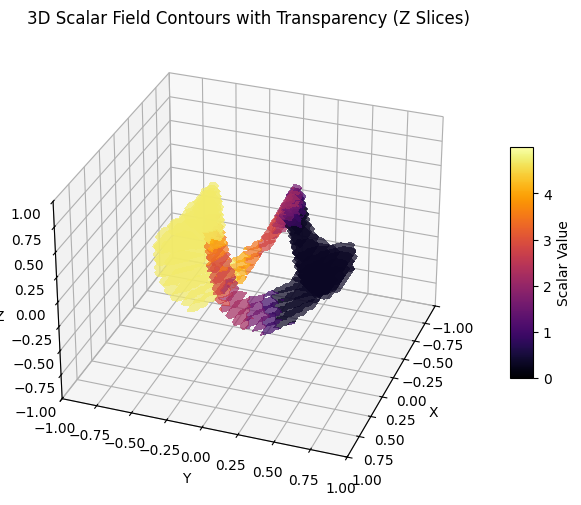

In [25]:
result_np_reshaped = np.array(result_jnp).reshape(mesh_x.shape)
create_plot_3d_sf(np.array(mesh_x), np.array(mesh_y), np.array(mesh_z), result_np_reshaped, t=0.001, num_slices=25)